In [131]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy.optimize import leastsq
from scipy.optimize import curve_fit
import os
import pandas as pd
from scipy.signal import find_peaks

In [141]:
def importeer(datanaam):
    x_as = []
    y_as = []

    # open file in read mode
    with open(datanaam, 'r', newline='') as file:

        # read and discard first line of file
        next(file)

        for line in file:
            # split column

            line_splitted = line.split(',')
            x = (float(line_splitted[3]))
            y = float(line_splitted[4])
            if x < 0.015:
                x_as.append(x)
                y_as.append(y)

    return x_as, y_as


def lorentz(x, x0, gamma, A):
    return A * ( gamma)**2 / ((x - x0)**2 + (gamma)**2)

def multi_lorentz(x, *params):
    B = params[-1]
    y = np.zeros_like(x, dtype=float) + B
    for i in range(0, len(params) - 1, 3):
        y += lorentz(x, params[i], params[i+1], params[i+2])
    return y


# ── Hoofd-fitfunctie ──────────────────────────────────────────────────────────

def lorentz_fit(x, y, x0_list, A_list,
                gamma_guess=0.001, B_guess=0.0,
                plot=True, title='Lorentz Fit'):
    
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x0_list) != len(A_list):
        raise ValueError("x0_list en A_list moeten even lang zijn.")

    # Startwaarden opbouwen
    p0 = []
    for x0, A in zip(x0_list, A_list):
        p0.extend([x0, gamma_guess, A])
    p0.append(B_guess)

    # Fit
    popt, pcov = curve_fit(multi_lorentz, x, y, p0=p0, maxfev=1000000)
    perr = np.sqrt(np.diag(pcov))
    y_fit = multi_lorentz(x, *popt)

    # Resultaten printen
    N = len(x0_list)
    print(f"{'─'*45}")
    for i in range(N):
        print(f"Piek {i+1}:")
        print(f"  x0    = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
        print(f"  gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
        print(f"  A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")
    print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")
    print(f"{'─'*45}")

    # Plot
    if plot:
        fig, ax = plt.subplots(figsize=(20, 10))
        ax.plot(x, y,     color= "#e1430e",  label='Data', lw=1.2)
        ax.plot(x, y_fit, color="#2fa20f", label='Lorentz fit', lw=1.8, ls='--')

        # Individuele pieken (stippellijnen)
        for i in range(N):
            x0_i, g_i, A_i = popt[i*3], popt[i*3+1], popt[i*3+2]
            B_i = popt[-1]
            y_i = lorentz(x, x0_i, g_i, A_i) + B_i
            ax.plot(x, y_i, lw=0.8, ls=':', label=f'Piek {i+1}')

        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Voltage (V)')
        ax.set_title(title)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return popt, perr

def lorentz_fit_2(x, y, x0_list, A_list,
                gamma_guess=0.001, B_guess=0.0,
                plot=True, title='Lorentz Fit'):
    
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x0_list) != len(A_list):
        raise ValueError("x0_list en A_list moeten even lang zijn.")

    # Startwaarden opbouwen
    p0 = []
    for x0, A in zip(x0_list, A_list):
        p0.extend([x0, gamma_guess, A])
    p0.append(B_guess)

    # Fit
    popt, pcov = curve_fit(multi_lorentz, x, y, p0=p0, maxfev=1000000)
    perr = np.sqrt(np.diag(pcov))
    y_fit = multi_lorentz(x, *popt)

    # Resultaten printen
    N = len(x0_list)
    print(f"{'─'*45}")
    for i in range(N):
        print(f"Piek {i+1}:")
        print(f"  x0    = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
        print(f"  gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
        print(f"  A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")
    print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")
    print(f"{'─'*45}")

    # Plot
    if plot:
        fig, ax = plt.subplots(figsize=(20, 10))
        ax.plot(x, y,     color='green',  label='Data', lw=1.2)
        ax.plot(x, y_fit, color='orange', label='Lorentz fit', lw=1.8, ls='--')

        # Individuele pieken (stippellijnen)
        for i in range(N):
            x0_i, g_i, A_i = popt[i*3], popt[i*3+1], popt[i*3+2]
            B_i = popt[-1]
            y_i = lorentz(x, x0_i, g_i, A_i) + B_i
            ax.plot(x, y_i, lw=0.8, ls=':', label=f'Piek {i+1}')

        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Voltage (V)')
        ax.set_title(title)
        ax.legend()
        plt.tight_layout()
        # plt.show()

    return popt, perr, x,y,y_fit

def subtract(x_foreground, y_foreground, x_background, y_background):
    y_interpolated = np.interp(x_foreground, x_background, y_background)
    y_subtracted = y_foreground - y_interpolated

    return x_foreground, y_subtracted


def load_file(number: int, folder_path) -> pd.DataFrame:

    filename = f"TEK{number:04d}.CSV"
    filepath = os.path.join(folder_path, filename)

    if not os.path.exists(filepath):
        print(f"Bestand niet gevonden: {filename}")
        return None

    df = pd.read_csv(
        filepath,
        header=None,
        usecols=[3, 4],
        names=["time", "voltage"],
        encoding="utf-8"
    )

    # Verwijder rijen waar time of voltage geen getal is (de metadata-rijen)
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)

    #print(f"Geladen: {filename} — {len(df)} datapunten")
    x_as = df["time"].values
    y_as = df["voltage"].values
    return x_as, y_as
def file_data(folder_path, N):
    x_subs = []
    y_subs = []

    block_size   = 5   # 10 paren per blok
    block_stride = 20   # sprong tussen blokken (10→30→50→...)
    fg_start     = 5   # eerste foreground index

    fg_block_start = fg_start

    while fg_block_start < N:
        for k in range(block_size):
            fg = fg_block_start + k        # foreground 10..19, 30..39, ...
            bg = fg - 10                   # background 0..9, 20..29, ...

            if fg >= N:
                break

            # Laad foreground & background
            result_fg = load_file(fg, folder_path)
            result_bg = load_file(bg, folder_path)

            if result_fg is None or result_bg is None:
                print(f"Overgeslagen: TEK{fg:04d} of TEK{bg:04d} niet gevonden.")
                continue

            x_foreground, y_foreground = result_fg
            x_background, y_background = result_bg

            # Subtract
            x_subtracted, y_subtracted = subtract(
                x_foreground, y_foreground,
                x_background, y_background
            )

            x_subs.append(x_subtracted)
            y_subs.append(y_subtracted)

            #plotten:
            plt.plot(x_subtracted, y_subtracted)
            plt.xlabel("Time (s)")
            plt.ylabel("Voltage (V)")
            plt.title(f"Voltage vs Time - TEK{fg:04d} - TEK{bg:04d}, subtracted")
            plt.show()

        # Volgend blok (10→30→50→...)
        fg_block_start += block_stride

    return x_subs, y_subs

def gemiddelde_grafiek(x_lijst, y_lijst):

    # Gemeenschappelijk x-bereik: van het hoogste minimum tot het laagste maximum
    # (zodat alle grafieken overlappen op dit bereik)
    x_min = max(np.min(x) for x in x_lijst)
    x_max = min(np.max(x) for x in x_lijst)

    # Aantal punten = gemiddelde lengte van de sub-lijsten
    n_punten = int(np.mean([len(x) for x in x_lijst]))

    x_communal = np.linspace(x_min, x_max, n_punten)

    # Interpoleer elke grafiek op het gemeenschappelijke x-grid
    y_geinterpoleerd = np.array([
        np.interp(x_communal, x, y)
        for x, y in zip(x_lijst, y_lijst)
    ])

    # Gemiddelde over alle grafieken
    y_gemiddeld = np.mean(y_geinterpoleerd, axis=0)

    return x_communal, y_gemiddeld

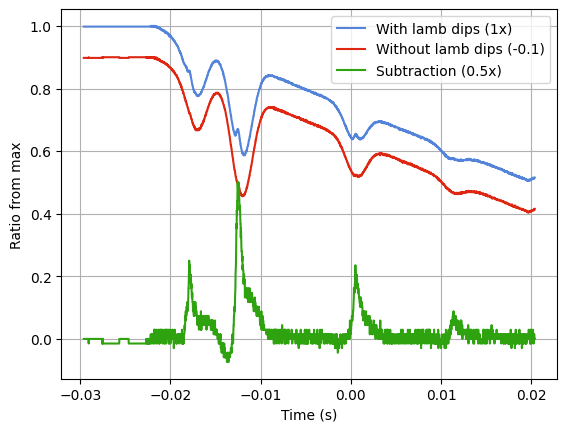

In [142]:
pad = r"/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Data/Full_spectrum_avg_4_2026_06_17"
x_full_fg, y_full_fg = load_file(1,pad)
x_full_bg, y_full_bg = load_file(0,pad)
x_sub, y_sub = subtract(x_full_fg,y_full_fg, x_full_bg, y_full_bg)


max_y_fg = max(y_full_fg)
max_y_bg = max(y_full_bg)
max_y_sub = max(y_sub)

y_array_fg = np.array(y_full_fg)
y_array_bg = np.array(y_full_bg)
y_array_sub = np.array(y_sub)

y_fg_ratios = y_array_fg/max_y_fg
y_bg_ratios = (y_array_bg/max_y_bg) - 0.1
y_sub_ratios = (y_array_sub/max_y_sub) *0.5

x_tikka = []
x_minna = min(x_sub)
x_maxxa = max(x_sub)
for i in np.arange(x_minna,x_maxxa,(x_maxxa-x_minna)/20):
    x_tikka.append(i)

# plt.figure(figsize= (20,4))
plt.plot(x_full_fg, y_fg_ratios, label = "With lamb dips (1x)", color = "#5483da")
plt.plot(x_full_bg, y_bg_ratios, label = "Without lamb dips (-0.1)", color = "#df2611")
plt.plot(x_sub, y_sub_ratios, label = "Subtraction (0.5x)", color = "#2fa20f")
# plt.xticks(x_tikka)
plt.grid()
plt.legend()
plt.ylabel("Ratio from max")
plt.xlabel ("Time (s)")
plt.show()

─────────────────────────────────────────────
Piek 1:
  x0    = -0.01783 ± 0.00001
  gamma = 0.00027 ± 0.00001
  A     = 0.19908 ± 0.00485
Piek 2:
  x0    = -0.01604 ± 0.00006
  gamma = 0.00122 ± 0.00013
  A     = 0.07097 ± 0.00352
Piek 3:
  x0    = -0.01288 ± 0.00022
  gamma = 0.00104 ± 0.00008
  A     = -0.25146 ± 0.08211
Piek 4:
  x0    = -0.01248 ± 0.00001
  gamma = 0.00040 ± 0.00003
  A     = 0.63680 ± 0.08014
Piek 5:
  x0    = -0.01122 ± 0.00010
  gamma = 0.00112 ± 0.00009
  A     = 0.15137 ± 0.02879
Piek 6:
  x0    = 0.00074 ± 0.00001
  gamma = 0.00055 ± 0.00001
  A     = 0.18206 ± 0.00328
Piek 7:
  x0    = 0.01165 ± 0.00004
  gamma = 0.00072 ± 0.00006
  A     = 0.05496 ± 0.00285
Achtergrond B = -0.00297 ± 0.00049
─────────────────────────────────────────────


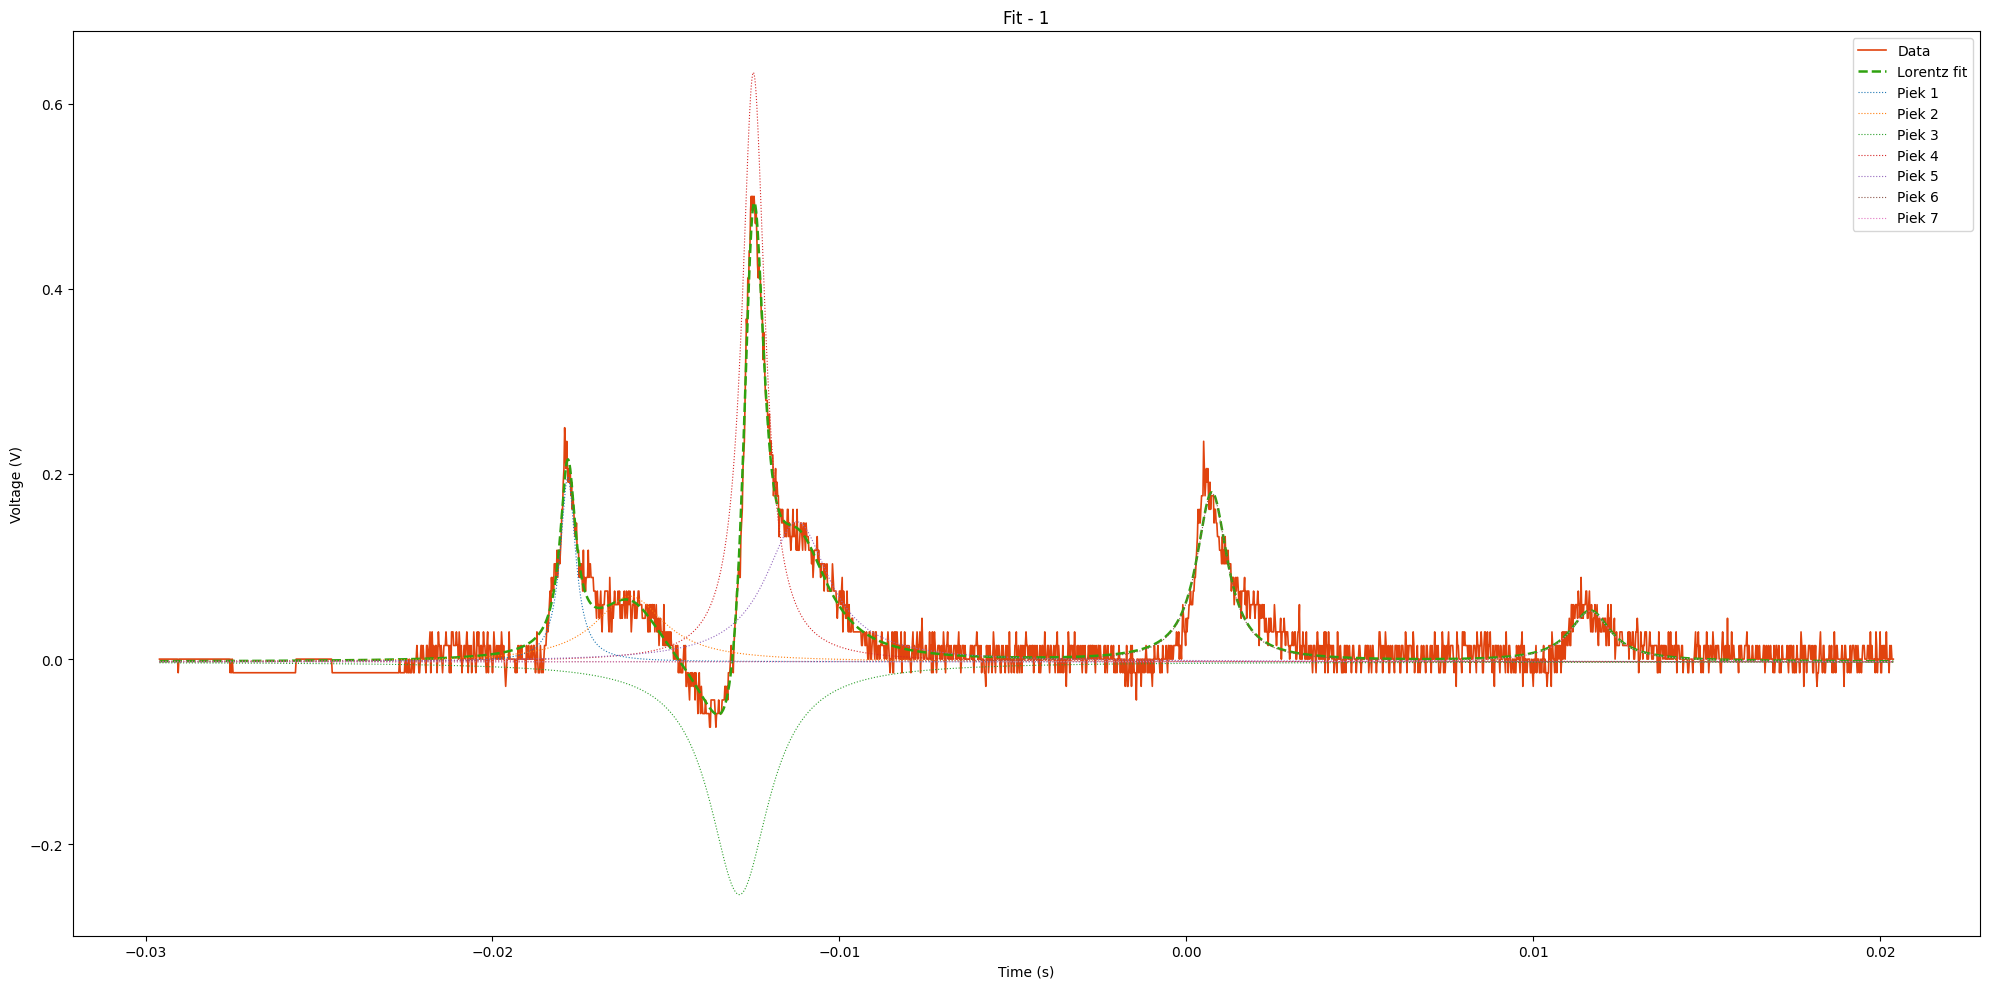

Chi²          = 2902.7972
Vrijheidsgraden (dof) = 2478
Gereduceerde chi²     = 1.1714
Chi²          = 1019.4823
Vrijheidsgraden (dof) = 2478
Gereduceerde chi²     = 0.4114


In [134]:
x0_1_list_sub  = [-0.0180, -0.017, -0.0140, -0.0130, -0.010, 0.00039, 0.0110]
A_1_list_sub   = [0.3, 0.1, -0.01, 0.5, 0.1, 0.2, 0.1]

popt_1_sub, perr_1_sub = lorentz_fit(
    x_sub, y_sub_ratios,
    x0_list     = x0_1_list_sub,
    A_list      = A_1_list_sub,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Fit - 1'
)
def gereduceerde_chi2(y, y_fit, n_params, sigma=None):

    residuen = np.asarray(y) - np.asarray(y_fit)

    if sigma is None:
        sigma = np.std(residuen)

    dof = len(y) - n_params
    chi2 = np.sum((residuen / sigma) ** 2)
    chi2_red = chi2 / dof

    print(f"Chi²          = {chi2:.4f}")
    print(f"Vrijheidsgraden (dof) = {dof}")
    print(f"Gereduceerde chi²     = {chi2_red:.4f}")

    return chi2_red

y_fit = multi_lorentz(x_sub, *popt_1_sub)
n_params = len(popt_1_sub)

chi2_red = gereduceerde_chi2(y_sub, y_fit, n_params)
# of met een bekende sigma:
chi2_red = gereduceerde_chi2(y_sub, y_fit, n_params, sigma=0.1)


[np.float64(-0.01782784728984535), np.float64(-0.012478706524375245), np.float64(0.0007387568247497204), np.float64(0.011645922274954087)]
0.0053491407654701045
9.75
1822.7226441559403
214.11067504018425
-528.0932086614789
─────────────────────────────────────────────
Piek 1:
  x0    = -0.01783 ± 0.00001
  gamma = 0.00027 ± 0.00001
  A     = 0.19908 ± 0.00485
Piek 2:
  x0    = -0.01604 ± 0.00006
  gamma = 0.00122 ± 0.00013
  A     = 0.07097 ± 0.00352
Piek 3:
  x0    = -0.01288 ± 0.00022
  gamma = 0.00104 ± 0.00008
  A     = -0.25146 ± 0.08211
Piek 4:
  x0    = -0.01248 ± 0.00001
  gamma = 0.00040 ± 0.00003
  A     = 0.63680 ± 0.08014
Piek 5:
  x0    = -0.01122 ± 0.00010
  gamma = 0.00112 ± 0.00009
  A     = 0.15137 ± 0.02879
Piek 6:
  x0    = 0.00074 ± 0.00001
  gamma = 0.00055 ± 0.00001
  A     = 0.18206 ± 0.00328
Piek 7:
  x0    = 0.01165 ± 0.00004
  gamma = 0.00072 ± 0.00006
  A     = 0.05496 ± 0.00285
Achtergrond B = -0.00297 ± 0.00049
─────────────────────────────────────────────


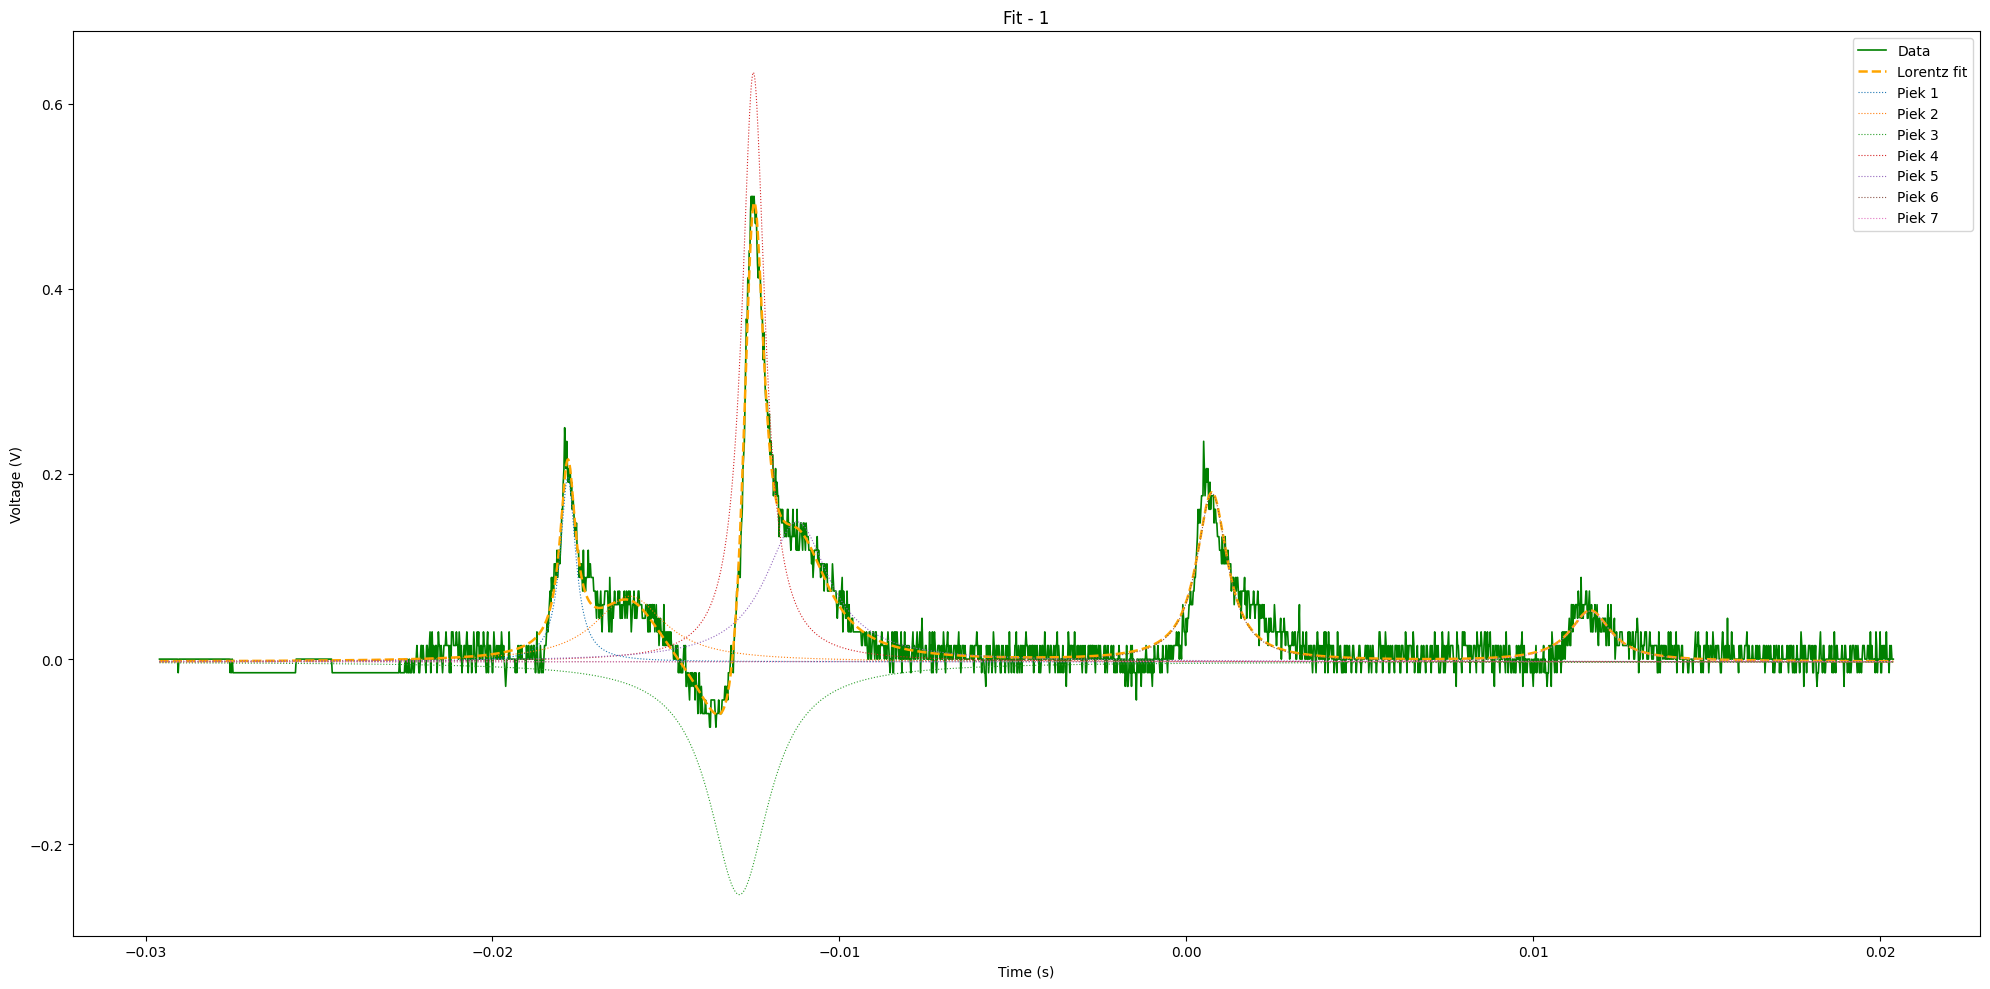

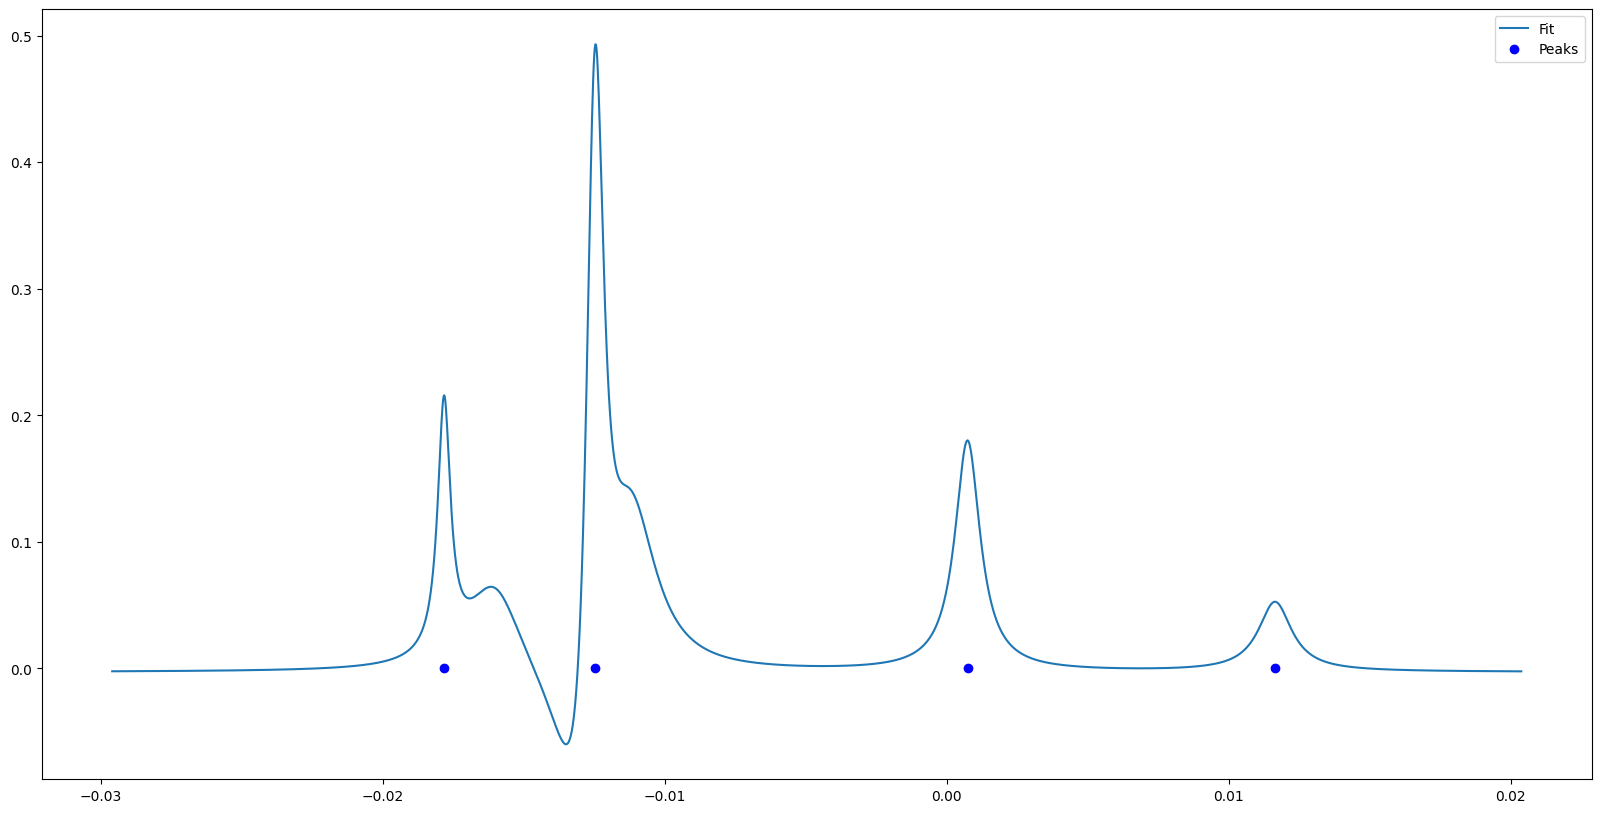

In [143]:
peaks = [popt_1_sub[0], popt_1_sub[9], popt_1_sub[15], popt_1_sub[18]]
print(peaks)


D1 = peaks[1]- peaks[0]
D2 = peaks[2]- peaks[1]
D3 = peaks[3]- peaks[2]
peak_1 = 372.71 #TerraHz
peak_2 = 382.46
peak_3 = 385.29
peak_4 = 379.53
D1_r = peak_2 - peak_1
D2_r = peak_3 - peak_2
D3_r = peak_4 - peak_3

print(D1)
print(D1_r)

step_1 = D1_r/D1
step_2 = D2_r/D2
step_3 = D3_r/D3

print(step_1)
print(step_2)
print(step_3)

x0_1_list_sub  = [-0.0180, -0.017, -0.0140, -0.0130, -0.010, 0.00039, 0.0110]
A_1_list_sub   = [0.3, 0.1, -0.01, 0.5, 0.1, 0.2, 0.1]

popt_1_sub, perr_1_sub, xthe, ythe, y_fit = lorentz_fit_2(
    x_sub, y_sub_ratios,
    x0_list     = x0_1_list_sub,
    A_list      = A_1_list_sub,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Fit - 1'
)

plt.figure(figsize=(20,10))
plt.plot(xthe, y_fit, label = "Fit")
plt.plot( peaks, [0,0,0,0], 'bo', label = "Peaks")
plt.legend()
plt.show()

─────────────────────────────────────────────
Piek 1:
  x0    = -0.00000 ± 0.00000
  gamma = 0.00027 ± 0.00000
  A     = 0.19908 ± 0.00000
Piek 2:
  x0    = 0.00179 ± 0.00000
  gamma = 0.00122 ± 0.00000
  A     = 0.07097 ± 0.00000
Piek 3:
  x0    = 0.00494 ± 0.00000
  gamma = -0.00104 ± 0.00000
  A     = -0.25146 ± 0.00000
Piek 4:
  x0    = 0.00535 ± 0.00000
  gamma = 0.00040 ± 0.00000
  A     = 0.63680 ± 0.00000
Piek 5:
  x0    = 0.00661 ± 0.00000
  gamma = 0.00112 ± 0.00000
  A     = 0.15137 ± 0.00000
Piek 6:
  x0    = 0.01857 ± 0.00000
  gamma = 0.00055 ± 0.00000
  A     = 0.18206 ± 0.00000
Piek 7:
  x0    = 0.02947 ± 0.00000
  gamma = 0.00072 ± 0.00000
  A     = 0.05496 ± 0.00000
Achtergrond B = -0.00297 ± 0.00000
─────────────────────────────────────────────


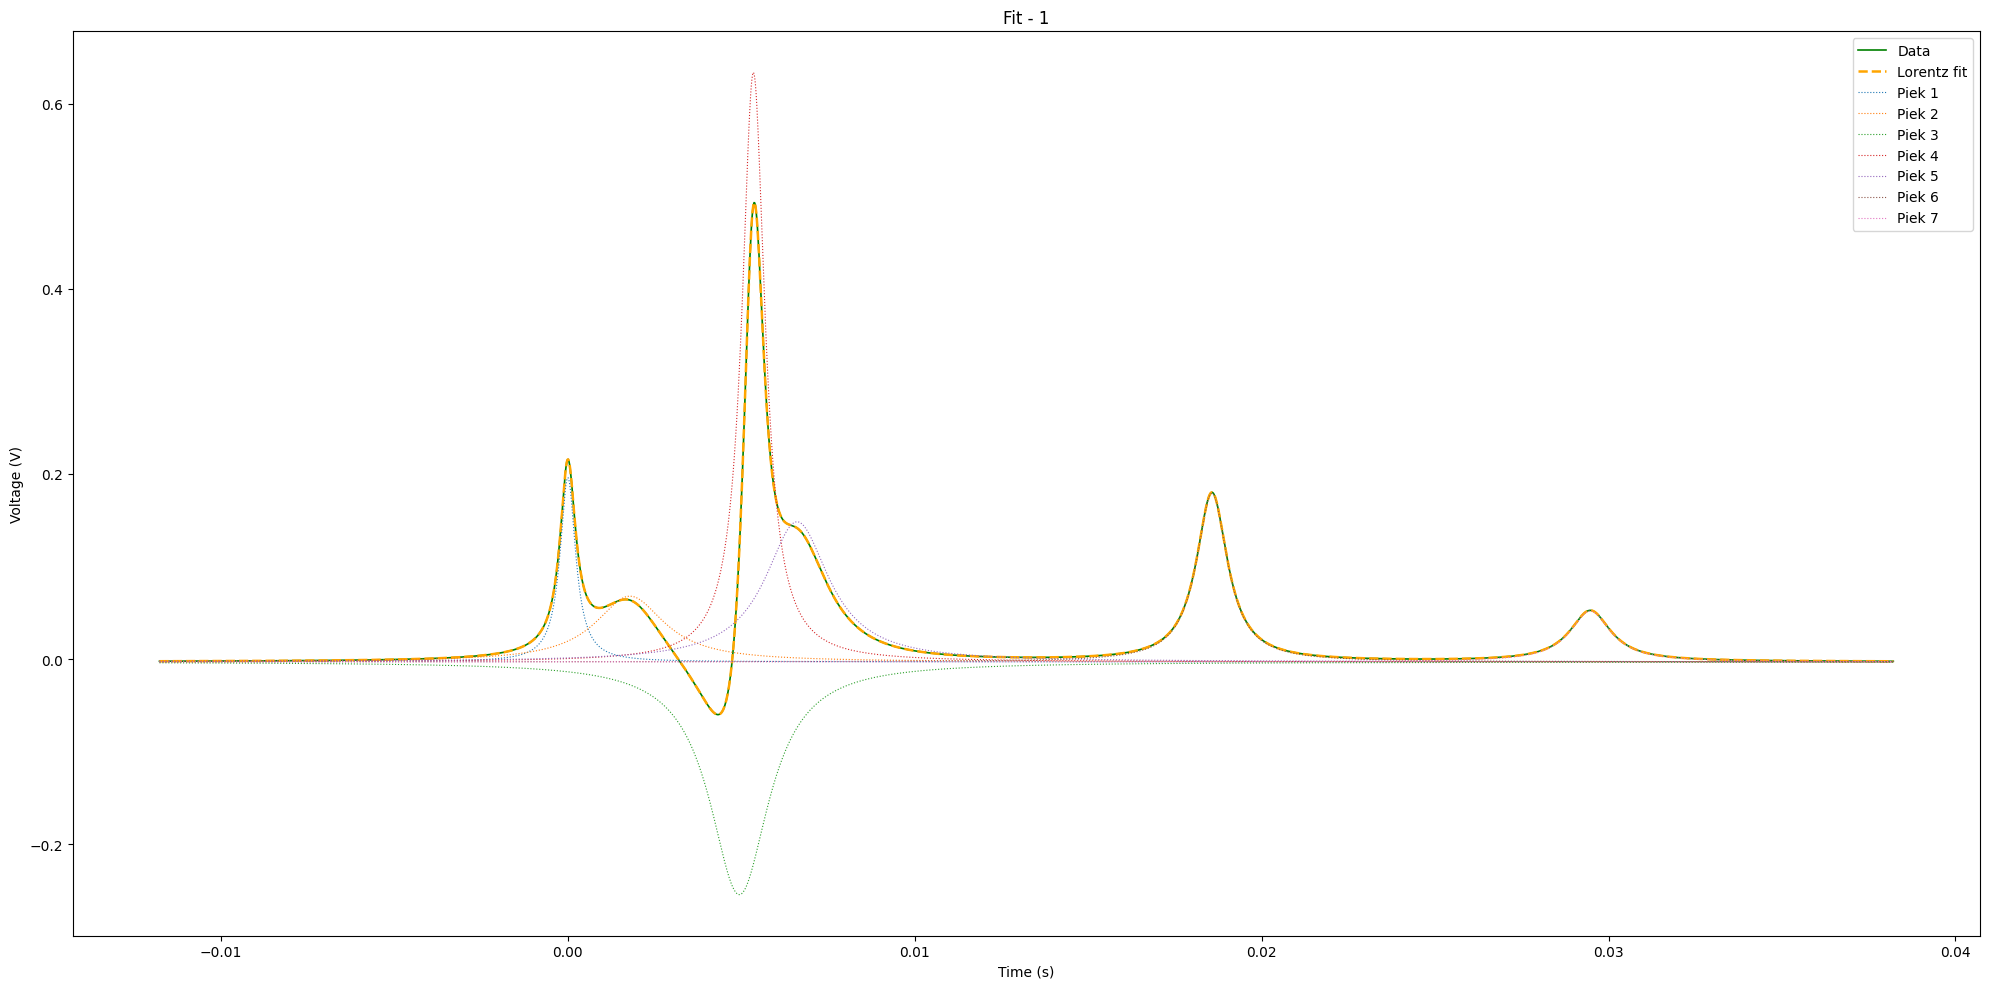

In [136]:
def subtract_x(x_list, value):
    x_real = []
    for i in range (0, len(x_list)):
        x = x_list[i]
        New_x = x - value
        x_real.append(New_x)
    return (x_real)

x_double_sub = subtract_x(x_sub,peaks[0])

peaks = [popt_1_sub[0], popt_1_sub[9], popt_1_sub[15], popt_1_sub[18]]

x0_double  = [-0.0180 - -0.01783, -0.017 - -0.01783, -0.0140 - -0.01783, -0.0130 - -0.01783, -0.010 - -0.01783, 0.00039 - -0.01783, 0.0110 - -0.01783]
A_double   = [0.3, 0.1, -0.01, 0.5, 0.1, 0.2, 0.1]

popt_1_double, perr_1_double, xdouble, ydouble, y_double_your_mom = lorentz_fit_2(
    x_double_sub, y_fit,
    x0_list     = x0_double,
    A_list      = A_double,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Fit - 1'
)



[np.float64(-7.605145927270235e-13), np.float64(0.005349140765465199), np.float64(0.018566604114594987), np.float64(0.02947376956479987)]
382.46
382.45999999999106


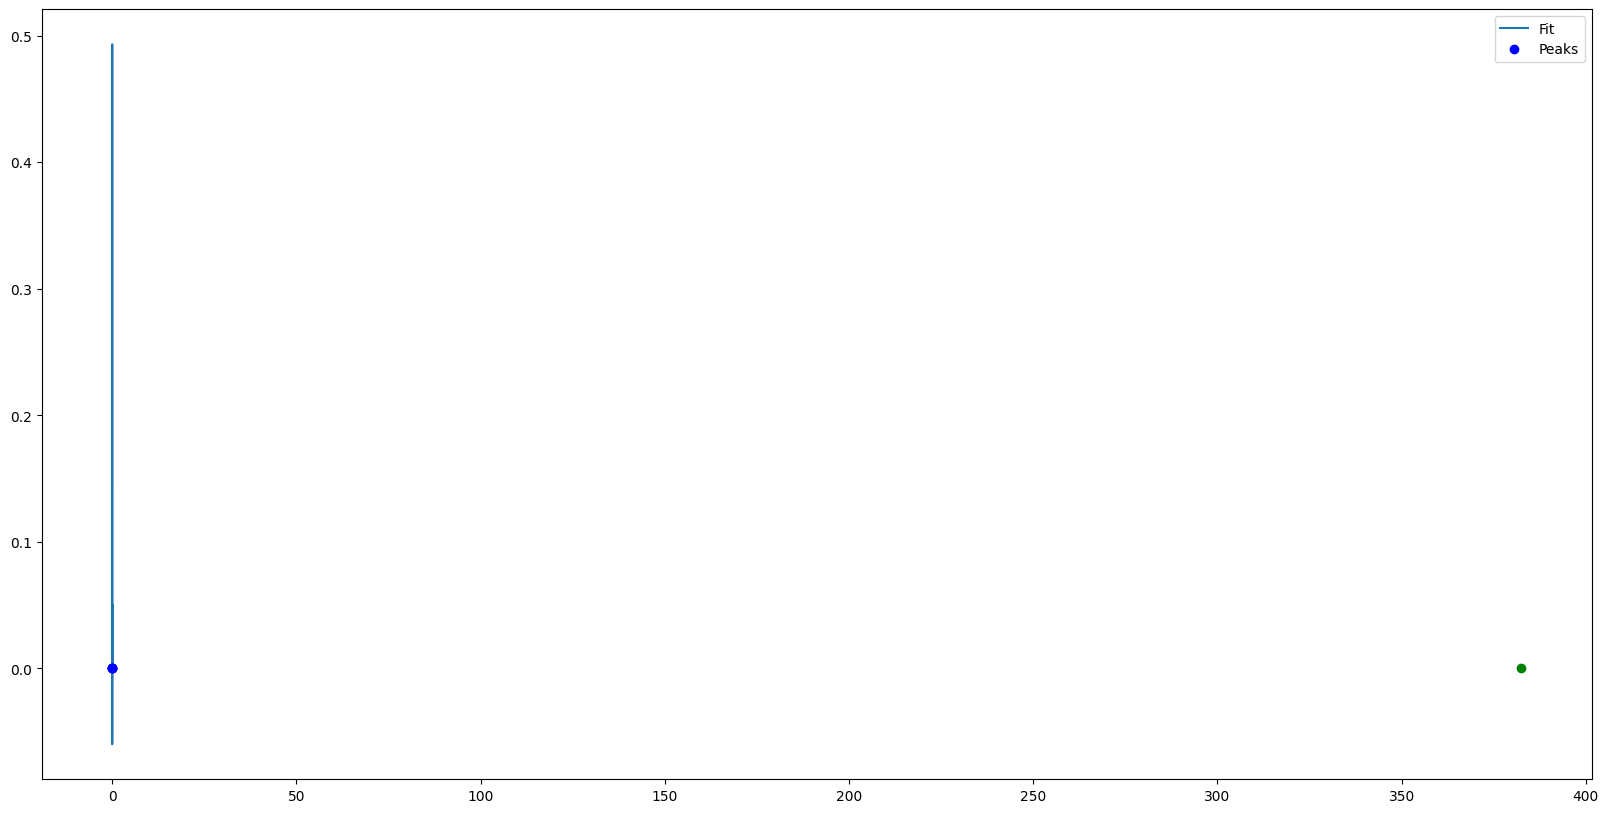

In [137]:
peaks_double = [popt_1_double[0], popt_1_double[9], popt_1_double[15], popt_1_double[18]]
print(peaks_double)

step_je = (peak_2 - peak_1) / D1          # scale: THz per x-unit
Peak_2_theo = peak_1 + peaks_double[1] * step_je
# Peak_3_theo = (peaks_double[2] - peaks_double[1] ) * ((382.46 - 371.71)/(peaks_double[2]-peaks_double[1]))
print(peak_2)
print(Peak_2_theo)


plt.figure(figsize=(20,10))
plt.plot(x_double_sub, y_fit, label = "Fit")
plt.plot( peaks_double, [0,0,0,0], 'bo', label = "Peaks")
# plt.plot(Peak_3_theo,0 ,'ro')
plt.plot(Peak_2_theo, 0 ,'go')
plt.legend()
plt.show()




Scale: 184.4586 THz per x-unit
Offset: 380.8240 THz
Peak 1: predicted = 377.5355 THz, reference = 372.7100 THz, diff = 4.8255 THz
Peak 2: predicted = 378.5222 THz, reference = 382.4600 THz, diff = -3.9378 THz
Peak 3: predicted = 380.9602 THz, reference = 385.2900 THz, diff = -4.3298 THz
Peak 4: predicted = 382.9722 THz, reference = 379.5300 THz, diff = 3.4422 THz


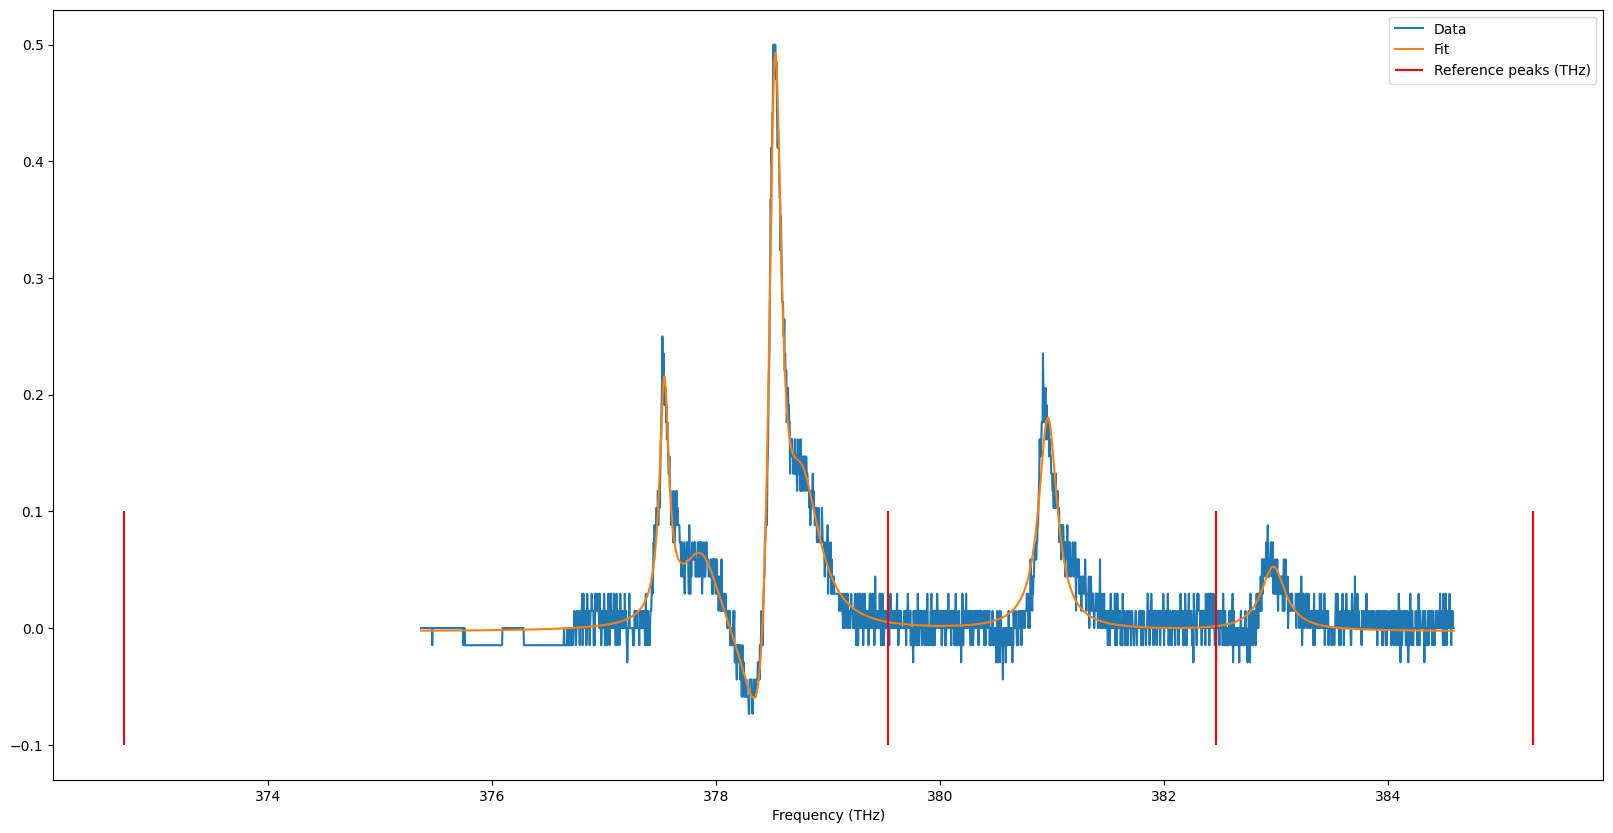

In [138]:
x_peaks = np.array(peaks)                          # fit coordinates
f_peaks = np.array([peak_1, peak_2, peak_3, peak_4])  # THz

# fit linear map: f = a*x + b
a, b = np.polyfit(x_peaks, f_peaks, 1)

print(f"Scale: {a:.4f} THz per x-unit")
print(f"Offset: {b:.4f} THz")

# convert your entire x-axis to THz
x_thz = a * np.array(x_sub) + b

# verify: predicted THz for each peak
for i, (x, f) in enumerate(zip(x_peaks, f_peaks)):
    f_pred = a * x + b
    print(f"Peak {i+1}: predicted = {f_pred:.4f} THz, reference = {f:.4f} THz, diff = {f_pred - f:.4f} THz")

# plot everything in THz
plt.figure(figsize=(20, 10))
plt.plot(x_thz, y_sub_ratios, label="Data")
plt.plot(x_thz, y_fit, label="Fit")
plt.vlines(f_peaks, ymin=-0.1, ymax=0.1, colors='r', label="Reference peaks (THz)")
plt.xlabel("Frequency (THz)")
plt.legend()
plt.show()